# Лабораторная работа №2. Нейронные сети


## Задание 1. Один нейрон на наборах nn_0 и nn_1
**Задание.** Постройте нейронную сеть из одного нейрона и обучите её на датасетах nn_0.csv и nn_1.csv. Насколько отличается результат обучения и почему? Сколько потребовалось эпох для обучения? Попробуйте различные функции активации и оптимизаторы.

**Данные.** В каждом файле два признака X1, X2 и метка класса −1 или 1. Файл nn_0a.csv в задании не назван, но устроен так же, как nn_0; он используется только для проверки нейрона на новых данных.

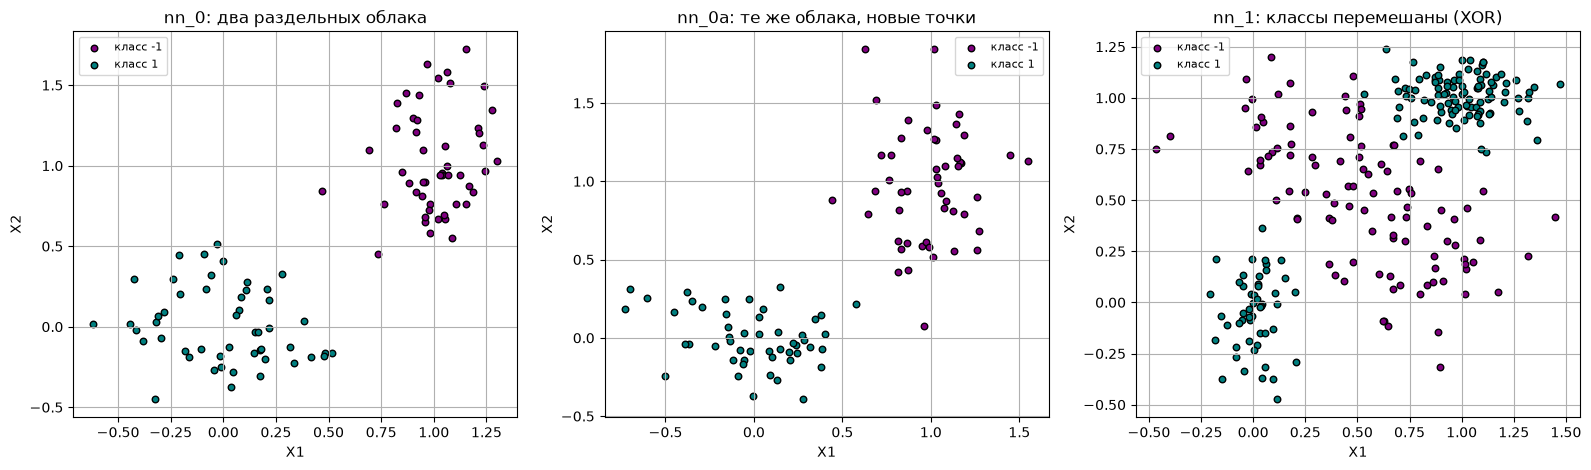

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

nn0 = pd.read_csv('nn_0.csv')
nn0a = pd.read_csv('nn_0a.csv')   # дополнительный набор того же вида, что nn_0
nn1 = pd.read_csv('nn_1.csv')

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
titles = ['nn_0: два раздельных облака', 'nn_0a: те же облака, новые точки', 'nn_1: классы перемешаны (XOR)']
for a, df, title in zip(ax, [nn0, nn0a, nn1], titles):
    for cls, color in [(-1, 'purple'), (1, 'teal')]:
        d = df[df['class'] == cls]
        a.scatter(d['X1'], d['X2'], color=color, edgecolor='k', s=22, label=f'класс {cls}')
    a.set_title(title)
    a.set_xlabel('X1')
    a.set_ylabel('X2')
    a.legend(fontsize=8)
    a.grid(True)
plt.tight_layout()
plt.show()

In [24]:
# Состав наборов и доля большего класса
nn0a = pd.read_csv('nn_0a.csv')   # дополнительный набор того же вида, что nn_0 (для проверки на новых данных)
for name, df in [('nn_0', nn0), ('nn_0a', nn0a), ('nn_1', nn1)]:
    counts = df['class'].value_counts()
    print(f'{name}: {len(df)} точек, класс −1: {counts[-1]}, класс 1: {counts[1]}, '
          f'доля большего класса: {counts.max() / len(df):.2f}')

nn_0: 100 точек, класс −1: 50, класс 1: 50, доля большего класса: 0.50
nn_0a: 100 точек, класс −1: 50, класс 1: 50, доля большего класса: 0.50
nn_1: 250 точек, класс −1: 100, класс 1: 150, доля большего класса: 0.60


### Один нейрон
Нейрон считает z = w1·x1 + w2·x2 + b и применяет функцию активации. Метка 1 кодируется как 1, метка −1 - как 0; функция потерь - бинарная кросс-энтропия (BCE). Чтобы использовать BCE для всех активаций, выход приводится к диапазону [0, 1]: sigmoid(z); (tanh(z) + 1) / 2; min(ReLU(z), 1). Обучение полным батчем (одна эпоха = один шаг по всей выборке), 500 эпох, начальные веса фиксированы (torch.manual_seed(42)). Основной запуск - сигмоида и Adam с шагом 0.05.

nn_0: accuracy = 1.0 , максимум впервые на эпохе 31
nn_1: accuracy = 0.416


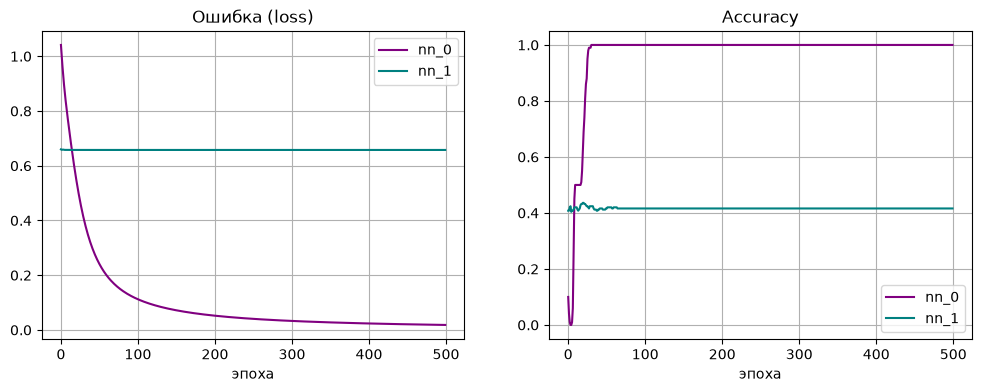

In [25]:
def to_tensors(df):
    X = torch.tensor(df[['X1', 'X2']].values, dtype=torch.float32)
    y = torch.tensor((df['class'] == 1).values, dtype=torch.float32).unsqueeze(1)
    return X, y

X0, y0 = to_tensors(nn0)
X1, y1 = to_tensors(nn1)

def train_neuron(X, y, activation='sigmoid', opt_name='adam', epochs=500, lr=0.05):
    torch.manual_seed(42)
    neuron = nn.Linear(2, 1)          # z = w1*x1 + w2*x2 + b
    act = {'sigmoid': torch.sigmoid,
           'tanh': lambda z: (torch.tanh(z) + 1) / 2,
           'relu': lambda z: torch.clamp(torch.relu(z), max=1)}[activation]
    opt = {'sgd': lambda p: optim.SGD(p, lr=lr),
           'momentum': lambda p: optim.SGD(p, lr=lr, momentum=0.9),   # SGD с моментом
           'adam': lambda p: optim.Adam(p, lr=lr),
           'rmsprop': lambda p: optim.RMSprop(p, lr=lr)}[opt_name](neuron.parameters())
    losses, accs = [], []
    for epoch in range(epochs):
        opt.zero_grad()
        out = act(neuron(X)).clamp(1e-7, 1 - 1e-7)
        loss = nn.BCELoss()(out, y)
        loss.backward()
        opt.step()
        losses.append(loss.item())
        accs.append(((out > 0.5).float() == y).float().mean().item())
    return neuron, losses, accs

n0, loss0, acc0 = train_neuron(X0, y0)
n1, loss1, acc1 = train_neuron(X1, y1)
print('nn_0: accuracy =', round(acc0[-1], 3), ', максимум впервые на эпохе', acc0.index(max(acc0)) + 1)
print('nn_1: accuracy =', round(acc1[-1], 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(loss0, color='purple', label='nn_0'); ax[0].plot(loss1, color='teal', label='nn_1')
ax[0].set_title('Ошибка (loss)'); ax[0].set_xlabel('эпоха')
ax[1].plot(acc0, color='purple', label='nn_0'); ax[1].plot(acc1, color='teal', label='nn_1')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('эпоха')
for a in ax:
    a.legend(); a.grid(True)
plt.show()

In [26]:
# Проверка нейрона, обученного на nn_0, на новых данных nn_0a
X0a, y0a = to_tensors(nn0a)
with torch.no_grad():
    acc_0a = ((torch.sigmoid(n0(X0a)) > 0.5).float() == y0a).float().mean().item()
print('nn_0a (не участвовал в обучении): accuracy =', round(acc_0a, 3))

# Почему на nn_1 accuracy ниже 0.6
with torch.no_grad():
    out1 = torch.sigmoid(n1(X1)).squeeze()
p = y1.mean().item()   # доля класса 1 в nn_1
print('Выходы нейрона на nn_1: от', round(out1.min().item(), 3), 'до', round(out1.max().item(), 3))
print('Доля точек, отнесённых к классу 1:', round((out1 > 0.5).float().mean().item(), 3))
print('loss нейрона:', round(loss1[-1], 3))
print('loss константы (всем точкам вероятность', round(p, 2), '):', round(-(p * np.log(p) + (1 - p) * np.log(1 - p)), 3))

nn_0a (не участвовал в обучении): accuracy = 1.0
Выходы нейрона на nn_1: от 0.408 до 0.725
Доля точек, отнесённых к классу 1: 0.816
loss нейрона: 0.658
loss константы (всем точкам вероятность 0.6 ): 0.673


### Сравнение функций активации и оптимизаторов
Оптимизаторы: SGD (обычный градиентный спуск), SGD с моментом 0.9 (учитывает направление предыдущих шагов), Adam и RMSprop (подбирают шаг отдельно для каждого веса). «Эпох до максимума» - первая эпоха, на которой достигнута максимальная accuracy.

In [27]:
# Все сочетания: 3 активации × 4 оптимизатора, шаг 0.05
rows = []
for name, X, y in [('nn_0', X0, y0), ('nn_1', X1, y1)]:
    for act in ['sigmoid', 'tanh', 'relu']:
        for opt_name in ['sgd', 'momentum', 'adam', 'rmsprop']:
            _, losses, accs = train_neuron(X, y, act, opt_name)
            rows.append({'данные': name, 'активация': act, 'оптимизатор': opt_name,
                         'accuracy': round(accs[-1], 3),
                         'макс. accuracy': round(max(accs), 3),
                         'эпох до максимума': accs.index(max(accs)) + 1})
pd.DataFrame(rows)

,данные,активация,оптимизатор,accuracy,макс. accuracy,эпох до максимума
0,nn_0,sigmoid,sgd,1.000,1.000,224
1,nn_0,sigmoid,momentum,1.000,1.000,36
2,nn_0,sigmoid,adam,1.000,1.000,31
3,nn_0,sigmoid,rmsprop,1.000,1.000,7
4,nn_0,tanh,sgd,1.000,1.000,68
5,nn_0,tanh,momentum,1.000,1.000,19
6,nn_0,tanh,adam,1.000,1.000,28
7,nn_0,tanh,rmsprop,1.000,1.000,7
8,nn_0,relu,sgd,0.500,0.500,2
9,nn_0,relu,momentum,0.500,0.500,2


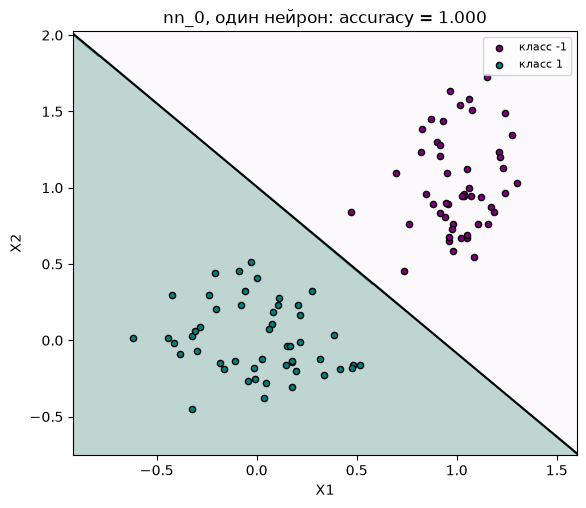

Прямая: -5.43·x1 + -4.97·x2 + 5.01 = 0


In [28]:
def plot_boundary(predict, df, ax, title):
    xx, yy = np.meshgrid(np.linspace(df['X1'].min() - 0.3, df['X1'].max() + 0.3, 200),
                         np.linspace(df['X2'].min() - 0.3, df['X2'].max() + 0.3, 200))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    with torch.no_grad():
        Z = (predict(grid) > 0.5).float().numpy().reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap='PuBuGn')
    for cls, color in [(-1, 'purple'), (1, 'teal')]:
        d = df[df['class'] == cls]
        ax.scatter(d['X1'], d['X2'], color=color, edgecolor='k', s=20, label=f'класс {cls}')
    ax.set_title(title)
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')
    ax.legend(fontsize=8)

# Разделяющая прямая одного нейрона на nn_0 (сигмоида, Adam)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
plot_boundary(lambda g: torch.sigmoid(n0(g)), nn0, ax, f'nn_0, один нейрон: accuracy = {acc0[-1]:.3f}')
w1, w2 = n0.weight.data[0].tolist()
b = n0.bias.item()
xs = np.linspace(nn0['X1'].min() - 0.3, nn0['X1'].max() + 0.3, 100)
ax.plot(xs, -(w1 * xs + b) / w2, color='black', linewidth=1.5)   # прямая w1·x1 + w2·x2 + b = 0
ax.set_ylim(nn0['X2'].min() - 0.3, nn0['X2'].max() + 0.3)
plt.show()
print(f'Прямая: {w1:.2f}·x1 + {w2:.2f}·x2 + {b:.2f} = 0')

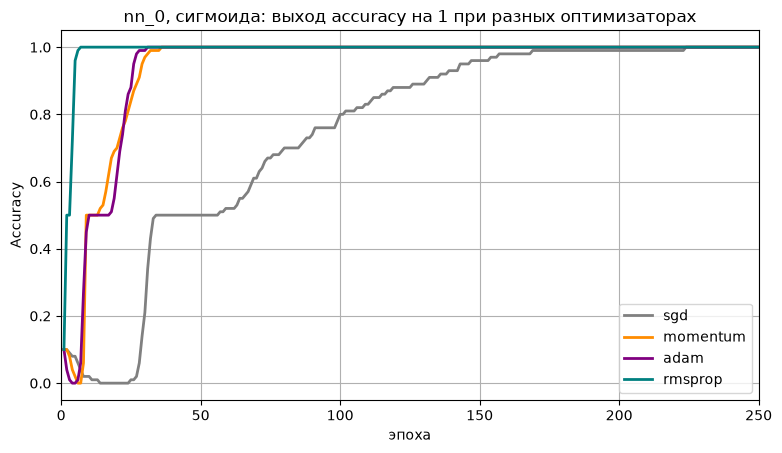

In [29]:
# nn_0, сигмоида: accuracy по эпохам для четырёх оптимизаторов (шаг 0.05)
plt.figure(figsize=(9, 4.8))
for opt_name, color in [('sgd', 'gray'), ('momentum', 'darkorange'), ('adam', 'purple'), ('rmsprop', 'teal')]:
    _, _, a = train_neuron(X0, y0, 'sigmoid', opt_name)
    plt.plot(range(1, len(a) + 1), a, color=color, linewidth=2, label=opt_name)
plt.xlim(0, 250)
plt.xlabel('эпоха')
plt.ylabel('Accuracy')
plt.title('nn_0, сигмоида: выход accuracy на 1 при разных оптимизаторах')
plt.legend()
plt.grid(True)
plt.show()

### Кривые обучения, шаг обучения и «мёртвый» ReLU

In [30]:
# Влияние шага обучения (lr)
lrs = [0.005, 0.01, 0.05, 0.1, 0.5]
epochs_tab, relu_tab = {}, {}
for opt_name in ['sgd', 'momentum', 'adam', 'rmsprop']:
    ep, rel = [], []
    for lr in lrs:
        _, _, accs = train_neuron(X0, y0, 'sigmoid', opt_name, lr=lr)
        ep.append(accs.index(1.0) + 1 if 1.0 in accs else '—')   # эпоха, когда accuracy впервые = 1
        _, _, accs_r = train_neuron(X0, y0, 'relu', opt_name, lr=lr)
        rel.append(round(accs_r[-1], 2))
    epochs_tab[opt_name] = ep
    relu_tab[opt_name] = rel
print('nn_0, sigmoid: эпоха, на которой accuracy впервые равна 1 («—» — не достигнута за 500 эпох)')
display(pd.DataFrame(epochs_tab, index=pd.Index(lrs, name='lr')))
print('nn_0, ReLU: итоговая accuracy')
display(pd.DataFrame(relu_tab, index=pd.Index(lrs, name='lr')))

nn_0, sigmoid: эпоха, на которой accuracy впервые равна 1 («—» — не достигнута за 500 эпох)


,sgd,momentum,adam,rmsprop
lr,,,,
0.005,—,231,198,81
0.010,—,120,104,30
0.050,224,36,31,7
0.100,113,25,20,6
0.500,24,11,8,5


nn_0, ReLU: итоговая accuracy


,sgd,momentum,adam,rmsprop
lr,,,,
0.005,0.5,0.5,0.31,0.5
0.010,0.5,0.5,0.81,0.5
0.050,0.5,0.5,0.50,0.5
0.100,0.5,0.5,0.50,0.5
0.500,0.5,0.5,0.50,0.5


In [31]:
# Почему ReLU «умирает»: первые эпохи при шаге 0.05 и 0.01 (Adam)
for lr in [0.05, 0.01]:
    neuron, losses, accs = train_neuron(X0, y0, 'relu', 'adam', lr=lr)
    with torch.no_grad():
        z = neuron(X0)
    print(f'lr = {lr}: accuracy по первым 8 эпохам {[round(a, 2) for a in accs[:8]]}, '
          f'итог {accs[-1]:.2f}; точек с z < 0 в конце: {(z < 0).float().mean().item():.0%}')

lr = 0.05: accuracy по первым 8 эпохам [0.01, 0.02, 0.07, 0.21, 0.36, 0.44, 0.5, 0.5], итог 0.50; точек с z < 0 в конце: 100%
lr = 0.01: accuracy по первым 8 эпохам [0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01], итог 0.81; точек с z < 0 в конце: 33%


### Лучшая прямая на nn_1

Лучший нейрон на nn_1: relu, momentum, lr = 0.05, accuracy = 0.788


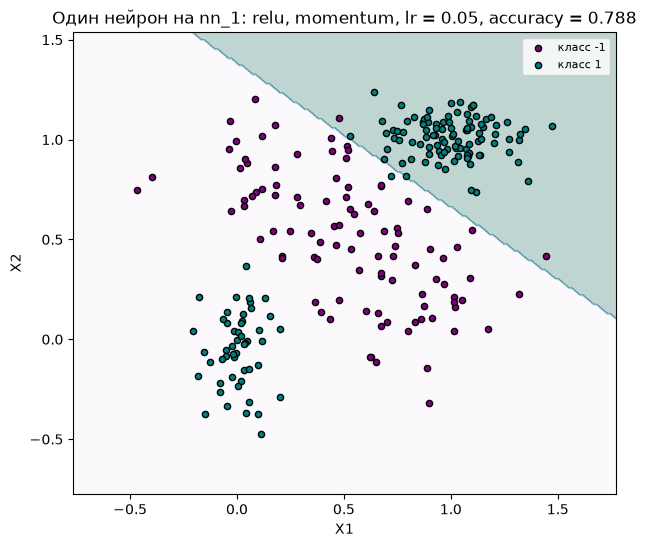

In [32]:
# Лучшая прямая одного нейрона на nn_1 (перебор активаций, оптимизаторов и шагов)
best = None
for act in ['sigmoid', 'tanh', 'relu']:
    for opt_name in ['sgd', 'momentum', 'adam', 'rmsprop']:
        for lr in [0.01, 0.05, 0.1, 0.5]:
            neuron, _, accs = train_neuron(X1, y1, act, opt_name, lr=lr)
            if best is None or accs[-1] > best[0]:
                best = (accs[-1], act, opt_name, lr, neuron)
acc_b, act_b, opt_b, lr_b, neuron_b = best
print(f'Лучший нейрон на nn_1: {act_b}, {opt_b}, lr = {lr_b}, accuracy = {acc_b:.3f}')

act_fn = {'sigmoid': torch.sigmoid,
          'tanh': lambda z: (torch.tanh(z) + 1) / 2,
          'relu': lambda z: torch.clamp(torch.relu(z), max=1)}
fig, ax = plt.subplots(figsize=(7, 6))
plot_boundary(lambda g: act_fn[act_b](neuron_b(g)), nn1, ax,
              f'Один нейрон на nn_1: {act_b}, {opt_b}, lr = {lr_b}, accuracy = {acc_b:.3f}')
plt.show()

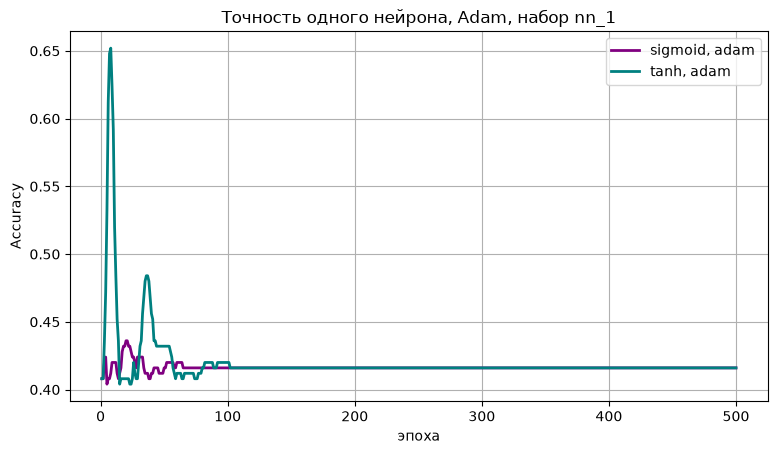

In [33]:
# nn_1, оптимизатор Adam: accuracy по эпохам для сигмоиды и tanh
plt.figure(figsize=(9, 4.8))
for act, color in [('sigmoid', 'purple'), ('tanh', 'teal')]:
    _, _, a1 = train_neuron(X1, y1, act, 'adam')
    plt.plot(range(1, len(a1) + 1), a1, color=color, linewidth=2, label=f'{act}, adam')
plt.xlabel('эпоха')
plt.ylabel('Accuracy')
plt.title('Точность одного нейрона, Adam, набор nn_1')
plt.legend()
plt.grid(True)
plt.show()

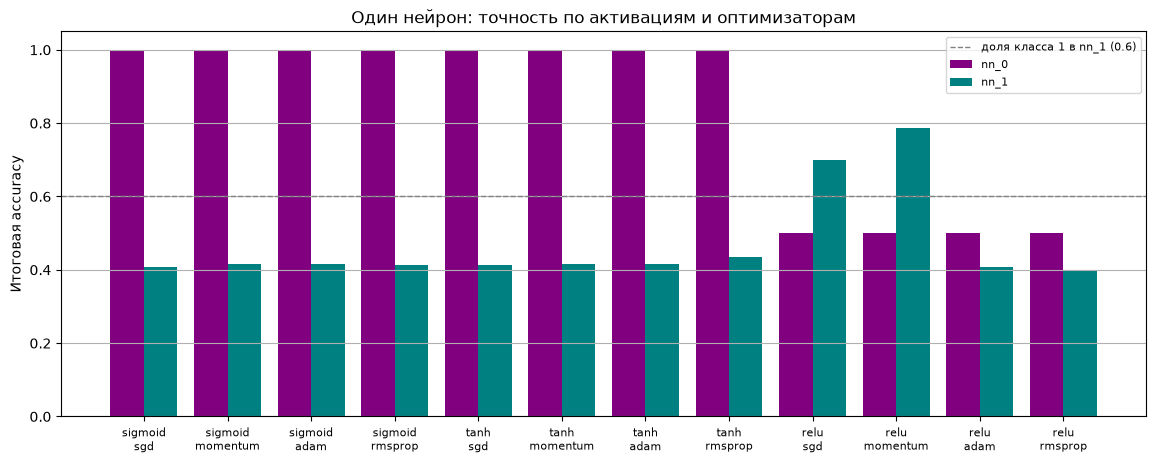

In [34]:
# Итоговая accuracy одного нейрона: все сочетания активации и оптимизатора на nn_0 и nn_1
res1 = pd.DataFrame(rows)
combos = [(act, opt_name) for act in ['sigmoid', 'tanh', 'relu'] for opt_name in ['sgd', 'momentum', 'adam', 'rmsprop']]
def get_acc(name, act, opt_name):
    part = res1[(res1['данные'] == name) & (res1['активация'] == act) & (res1['оптимизатор'] == opt_name)]
    return part['accuracy'].item()
x = np.arange(len(combos))
plt.figure(figsize=(14, 5))
plt.bar(x - 0.2, [get_acc('nn_0', a, o) for a, o in combos], width=0.4, color='purple', label='nn_0')
plt.bar(x + 0.2, [get_acc('nn_1', a, o) for a, o in combos], width=0.4, color='teal', label='nn_1')
plt.axhline(0.6, linestyle='--', color='gray', linewidth=1, label='доля класса 1 в nn_1 (0.6)')
plt.xticks(x, [f'{a}\n{o}' for a, o in combos], fontsize=8)
plt.ylabel('Итоговая accuracy')
plt.title('Один нейрон: точность по активациям и оптимизаторам')
plt.legend(fontsize=8)
plt.grid(True, axis='y')
plt.show()

### Выводы по заданию 1
Один и тот же нейрон ведёт себя на двух наборах принципиально по-разному. На линейно разделимом nn_0 один нейрон находит разделяющую прямую и классифицирует без ошибок как обучающие точки, так и новые данные nn_0a; с сигмоидой и Adam для этого потребовалась 31 эпоха. На nn_1 классы образуют структуру XOR, и никакая прямая не может отделить оба сгустка класса 1 от класса -1: итоговая accuracy 0.40–0.44 у сигмоиды и tanh, лучшая найденная прямая даёт 0.788. Различие объясняется самим устройством нейрона - его граница всегда прямая, - а не плохим подбором параметров.

От выбора функции активации и оптимизатора зависят скорость и устойчивость обучения, но граница при любом выборе остаётся прямой. Сигмоида и tanh на nn_0 одинаково доходят до accuracy 1, tanh немного быстрее. Число эпох определяется оптимизатором и скоростью обучения: от 5 (RMSprop, скорость 0.5) до 224 (SGD, 0.05), а при малой скорости обычный SGD не успевает за 500 эпох. ReLU в одиночном нейроне может «умереть», если большой шаг переводит все точки в область, где градиент равен нулю. На nn_1 сигмоида с кросс-энтропией заканчивает обучение даже хуже константы, потому что минимизирует потери, а не число ошибок.

## Задание 2. Сеть с минимальной ошибкой на nn_1
**Задание.** Постройте другую нейронную сеть, чтобы достичь минимальной ошибки на датасете nn_1.csv. Объясните выбор гиперпараметров построенной нейронной сети.

**Методика.** Набор nn_1 разделён на обучающую (175 точек) и тестовую (75 точек) выборки, 70/30 с сохранением долей классов. Перебраны 8 архитектур скрытой части (один слой из 2, 4, 8, 16, 32 нейронов и два слоя 8-8, 16-16, 32-16), две функции активации скрытых слоёв (ReLU, tanh) и два оптимизатора (Adam с шагом 0.01; SGD с моментом 0.9 и шагом 0.1). Выходной слой - один нейрон с сигмоидой, функция потерь BCE, 2000 эпох полным батчем. «Эпоха*» - первая эпоха, на которой accuracy на тестовой выборке достигла максимума.

In [35]:
from sklearn.model_selection import train_test_split

# 70 % точек — обучающая выборка, 30 % — тестовая (с сохранением долей классов)
idx_tr, idx_te = train_test_split(np.arange(len(nn1)), test_size=0.3, random_state=42, stratify=nn1['class'])

# Подбор гиперпараметров: архитектура, функция активации, оптимизатор
def make_mlp(hidden, act):
    layers, n_in = [], 2
    for h in hidden:
        layers += [nn.Linear(n_in, h), nn.ReLU() if act == 'relu' else nn.Tanh()]
        n_in = h
    layers += [nn.Linear(n_in, 1), nn.Sigmoid()]
    return nn.Sequential(*layers)

def train_mlp(hidden, act, opt_name, epochs=2000):
    torch.manual_seed(42)
    model = make_mlp(hidden, act)
    if opt_name == 'adam':
        opt = optim.Adam(model.parameters(), lr=0.01)
    else:
        opt = optim.SGD(model.parameters(), lr=0.1, momentum=0.9)
    hist = {'loss_tr': [], 'loss_te': [], 'acc_tr': [], 'acc_te': []}
    for epoch in range(epochs):
        opt.zero_grad()
        loss = nn.BCELoss()(model(X1[idx_tr]), y1[idx_tr])
        loss.backward()
        opt.step()
        with torch.no_grad():
            for part, idx in [('tr', idx_tr), ('te', idx_te)]:
                out = model(X1[idx])
                hist['loss_' + part].append(nn.BCELoss()(out, y1[idx]).item())
                hist['acc_' + part].append(((out > 0.5).float() == y1[idx]).float().mean().item())
    return model, hist

configs = [[2], [4], [8], [16], [32], [8, 8], [16, 16], [32, 16]]
search = []
for hidden in configs:
    for act in ['relu', 'tanh']:
        for opt_name in ['adam', 'sgd_momentum']:
            model, hist = train_mlp(hidden, act, opt_name)
            search.append({'скрытые слои': '-'.join(map(str, hidden)),
                           'активация': act,
                           'оптимизатор': opt_name,
                           'параметров': sum(p.numel() for p in model.parameters()),
                           'accuracy train': round(hist['acc_tr'][-1], 3),
                           'accuracy test': round(hist['acc_te'][-1], 3),
                           'макс. accuracy test': round(max(hist['acc_te']), 3),
                           'эпоха*': int(np.argmax(hist['acc_te'])) + 1})
search = pd.DataFrame(search)
search

,скрытые слои,активация,оптимизатор,параметров,accuracy train,accuracy test,макс. accuracy test,эпоха*
0,2,relu,adam,9,0.989,0.987,0.987,296
1,2,relu,sgd_momentum,9,0.983,0.987,0.987,233
2,2,tanh,adam,9,0.989,0.987,0.987,177
3,2,tanh,sgd_momentum,9,0.989,0.987,0.987,131
4,4,relu,adam,17,1.000,0.987,1.000,512
5,4,relu,sgd_momentum,17,1.000,0.987,0.987,172
6,4,tanh,adam,17,1.000,0.973,0.987,319
7,4,tanh,sgd_momentum,17,1.000,0.973,0.987,141
8,8,relu,adam,33,1.000,0.987,1.000,862
9,8,relu,sgd_momentum,33,1.000,0.987,0.987,121


### Выбранная сеть

Сеть 2-8-1: accuracy train 1.0  test 0.987  на всех 250 точках 0.996 (ошибок: 1 )
Эпоха, на которой accuracy на тесте впервые максимальна: 121


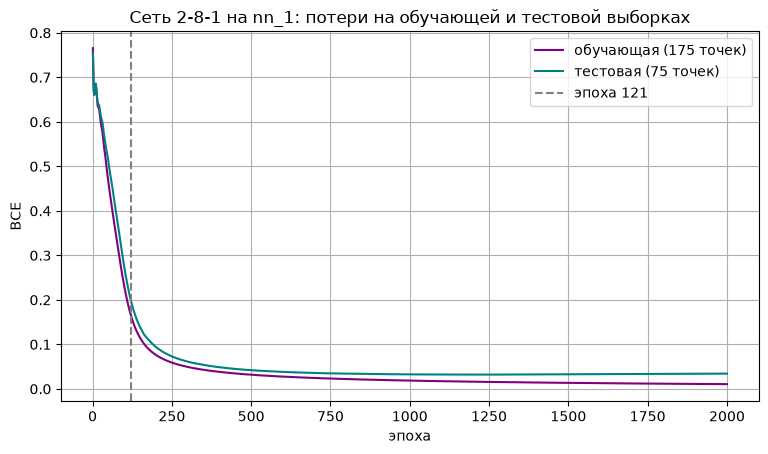

In [36]:
# Выбранная сеть: 2-8-1, ReLU, SGD с моментом
mlp, hist = train_mlp([8], 'relu', 'sgd_momentum')
best_epoch = int(np.argmax(hist['acc_te'])) + 1
with torch.no_grad():
    acc_all = ((mlp(X1) > 0.5).float() == y1).float().mean().item()
print('Сеть 2-8-1: accuracy train', round(hist['acc_tr'][-1], 3), ' test', round(hist['acc_te'][-1], 3),
      ' на всех 250 точках', round(acc_all, 3), '(ошибок:', round((1 - acc_all) * 250), ')')
print('Эпоха, на которой accuracy на тесте впервые максимальна:', best_epoch)

plt.figure(figsize=(9, 4.8))
plt.plot(range(1, len(hist['loss_tr']) + 1), hist['loss_tr'], color='purple', label='обучающая (175 точек)')
plt.plot(range(1, len(hist['loss_te']) + 1), hist['loss_te'], color='teal', label='тестовая (75 точек)')
plt.axvline(best_epoch, linestyle='--', color='gray', label=f'эпоха {best_epoch}')
plt.xlabel('эпоха')
plt.ylabel('BCE')
plt.title('Сеть 2-8-1 на nn_1: потери на обучающей и тестовой выборках')
plt.legend()
plt.grid(True)
plt.show()

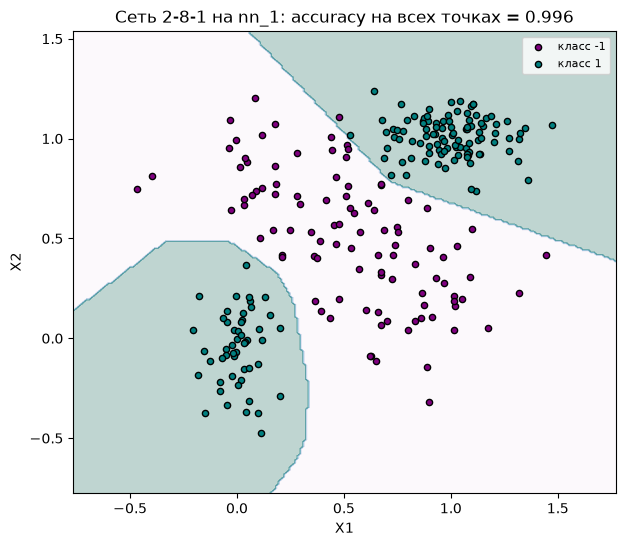

In [37]:
# Граница решений выбранной сети 2-8-1 на nn_1
fig, ax = plt.subplots(figsize=(7, 6))
plot_boundary(mlp, nn1, ax, f'Сеть 2-8-1 на nn_1: accuracy на всех точках = {acc_all:.3f}')
plt.show()

### Выводы по заданию 2
На nn_1 удалось получить одну ошибку из 75 точек тестовой выборки (accuracy 0.987) и одну из 250 на всём наборе (0.4 %); меньше не получается ни у одной из 32 сетей. Её даёт сеть 2-8-1 с ReLU и SGD с моментом 0.9 и скоростью 0.1. Гиперпараметры взяты из перебора 32 сетей: среди сетей с минимальной итоговой ошибкой на тесте выбрана небольшая и устойчивая к выбору активации, которая быстро обучается.

Без скрытого слоя задачу не решить, так как граница одного нейрона - прямая. Уже два скрытых нейрона образуют полосу между двумя прямыми и решают задачу XOR, а более крупные сети ошибку не уменьшают: оставшаяся точка лежит в зоне перекрытия классов. При этом та же функция потерь, которая в задании 1 приводила одиночный нейрон к accuracy ниже константы, здесь работает нормально: у сети достаточно свободы, чтобы при минимальных потерях не было и ошибок.

## Задание 3. Свёрточный классификатор MNIST
**Задание.** Создайте классификатор на базе свёрточной нейронной сети для набора данных MNIST. Приведите архитектуру полученной свёрточной нейронной сети (количество свёрточных слоёв с размерами, какой был пулинг и т.д.). Оцените качество классификации. Визуализируйте фильтры (filters) и результирующие признаки (feature maps).

**Данные.** MNIST - рукописные цифры 0–9, изображения 28×28 в оттенках серого: 60 000 в обучающей и 10 000 в тестовой выборке. Загрузка через torchvision.datasets.MNIST, яркость нормализуется (среднее 0.1307, стандартное отклонение 0.3081).

**Обучение.** Функция потерь - кросс-энтропия (CrossEntropyLoss), оптимизатор Adam с шагом 0.001, батч 128 изображений, 6 эпох. Loss и accuracy на обучающей выборке усредняются по батчам в течение эпохи, на тестовой - считаются после эпохи.

In [38]:
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader

transform = T.Compose([T.ToTensor(), T.Normalize((0.1307,), (0.3081,))])
train_set = torchvision.datasets.MNIST('mnist_data', train=True, download=True, transform=transform)
test_set = torchvision.datasets.MNIST('mnist_data', train=False, download=True, transform=transform)
print('train:', len(train_set), ' test:', len(test_set))

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)    # 16 фильтров 3×3
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)   # 32 фильтра 3×3
        self.pool = nn.MaxPool2d(2)                                # 28 → 14 → 7
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)
    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = torch.relu(self.fc1(x.flatten(1)))
        return self.fc2(x)

torch.manual_seed(42)
cnn = CNN()
print(cnn)
opt = optim.Adam(cnn.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()
train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
test_loader = DataLoader(test_set, batch_size=1000)

history = []
for epoch in range(6):
    cnn.train()
    loss_sum, correct_tr = 0, 0
    for xb, yb in train_loader:
        opt.zero_grad()
        out = cnn(xb)
        loss = loss_fn(out, yb)
        loss.backward()
        opt.step()
        loss_sum += loss.item() * len(yb)
        correct_tr += (out.argmax(1) == yb).sum().item()
    cnn.eval()
    loss_te, correct = 0, 0
    with torch.no_grad():
        for xb, yb in test_loader:
            out = cnn(xb)
            loss_te += loss_fn(out, yb).item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item()
    history.append({'эпоха': epoch + 1,
                    'loss train': loss_sum / len(train_set),
                    'accuracy train': correct_tr / len(train_set),
                    'loss test': loss_te / len(test_set),
                    'accuracy test': correct / len(test_set)})
    print(f'Эпоха {epoch + 1}: accuracy на тесте = {correct / len(test_set):.4f}')

history = pd.DataFrame(history).set_index('эпоха')
history.round(4)

train: 60000  test: 10000
CNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Эпоха 1: accuracy на тесте = 0.9768
Эпоха 2: accuracy на тесте = 0.9871
Эпоха 3: accuracy на тесте = 0.9882
Эпоха 4: accuracy на тесте = 0.9877
Эпоха 5: accuracy на тесте = 0.9882
Эпоха 6: accuracy на тесте = 0.9863


,loss train,accuracy train,loss test,accuracy test
эпоха,,,,
1,0.2218,0.9343,0.0683,0.9768
2,0.0596,0.9817,0.0394,0.9871
3,0.0425,0.9871,0.0343,0.9882
4,0.0328,0.9897,0.0359,0.9877
5,0.0255,0.9920,0.0335,0.9882
6,0.0200,0.9936,0.0431,0.9863


In [39]:
# Архитектура: размер выхода и число параметров каждого слоя
def n_params(layer):
    return sum(p.numel() for p in layer.parameters())

x = torch.zeros(1, 1, 28, 28)
arch = [('вход', tuple(x.shape[1:]), 0)]
x = torch.relu(cnn.conv1(x)); arch.append(('conv1: 16 фильтров 3×3, padding 1 + ReLU', tuple(x.shape[1:]), n_params(cnn.conv1)))
x = cnn.pool(x);              arch.append(('MaxPool 2×2', tuple(x.shape[1:]), 0))
x = torch.relu(cnn.conv2(x)); arch.append(('conv2: 32 фильтра 3×3, padding 1 + ReLU', tuple(x.shape[1:]), n_params(cnn.conv2)))
x = cnn.pool(x);              arch.append(('MaxPool 2×2', tuple(x.shape[1:]), 0))
x = x.flatten(1);             arch.append(('разворот в вектор (flatten)', tuple(x.shape[1:]), 0))
x = torch.relu(cnn.fc1(x));   arch.append(('fc1: полносвязный + ReLU', tuple(x.shape[1:]), n_params(cnn.fc1)))
x = cnn.fc2(x);               arch.append(('fc2: полносвязный (выход, 10 классов)', tuple(x.shape[1:]), n_params(cnn.fc2)))
print('Всего параметров:', n_params(cnn))
pd.DataFrame(arch, columns=['слой', 'размер выхода', 'параметров'])

Всего параметров: 206922


,слой,размер выхода,параметров
0,вход,"(1, 28, 28)",0
1,"conv1: 16 фильтров 3×3, padding 1 + ReLU","(16, 28, 28)",160
2,MaxPool 2×2,"(16, 14, 14)",0
3,"conv2: 32 фильтра 3×3, padding 1 + ReLU","(32, 14, 14)",4640
4,MaxPool 2×2,"(32, 7, 7)",0
5,разворот в вектор (flatten),"(1568,)",0
6,fc1: полносвязный + ReLU,"(128,)",200832
7,"fc2: полносвязный (выход, 10 классов)","(10,)",1290


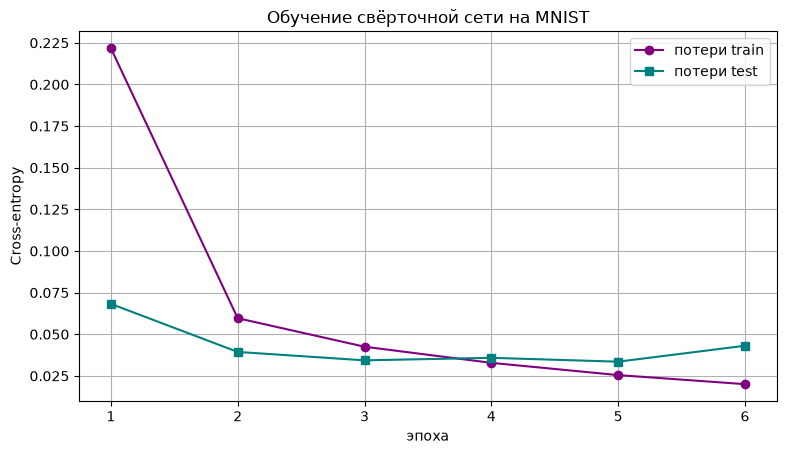

In [40]:
# Потери свёрточной сети на обучающей и тестовой выборках
plt.figure(figsize=(9, 4.8))
plt.plot(history.index, history['loss train'], marker='o', color='purple', label='потери train')
plt.plot(history.index, history['loss test'], marker='s', color='teal', label='потери test')
plt.xlabel('эпоха')
plt.ylabel('Cross-entropy')
plt.title('Обучение свёрточной сети на MNIST')
plt.legend()
plt.grid(True)
plt.show()

### Качество классификации, фильтры и карты признаков

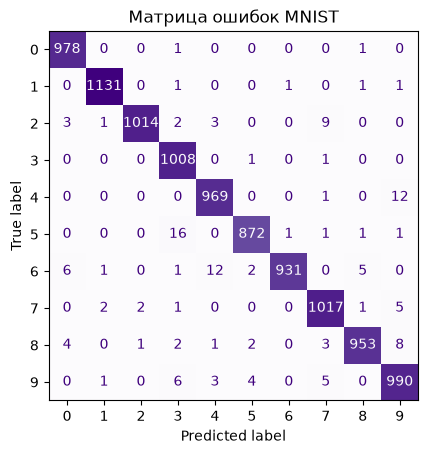

Ошибок: 137 из 10000


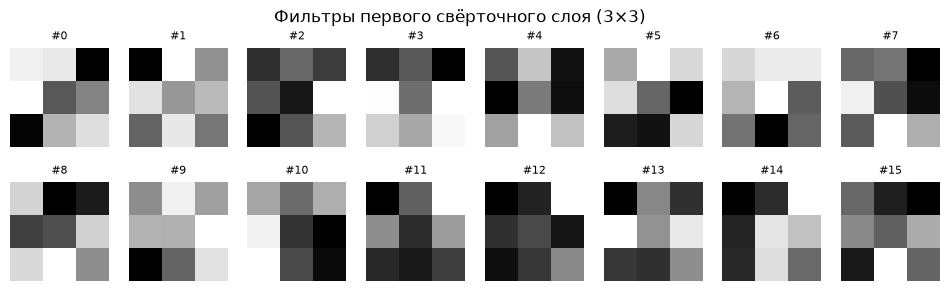

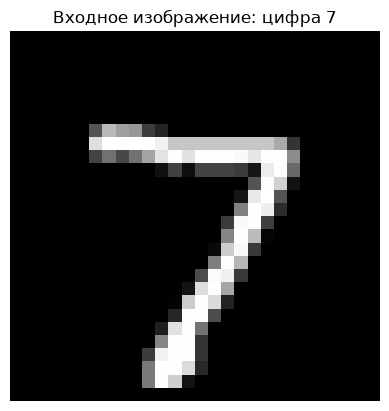

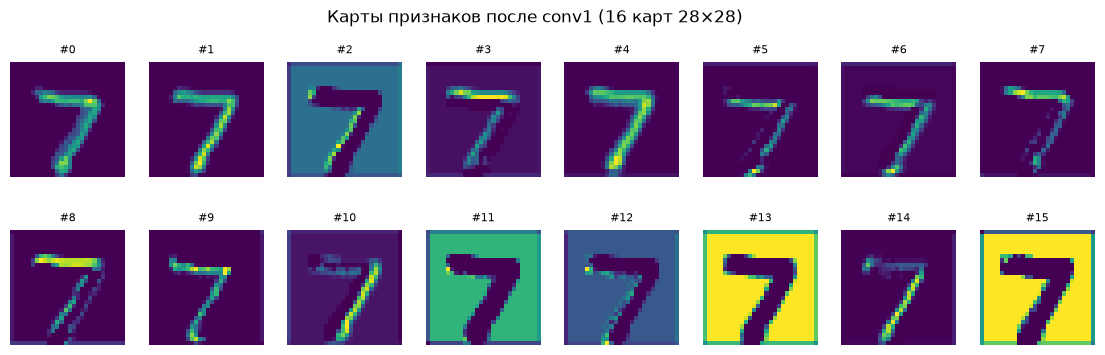

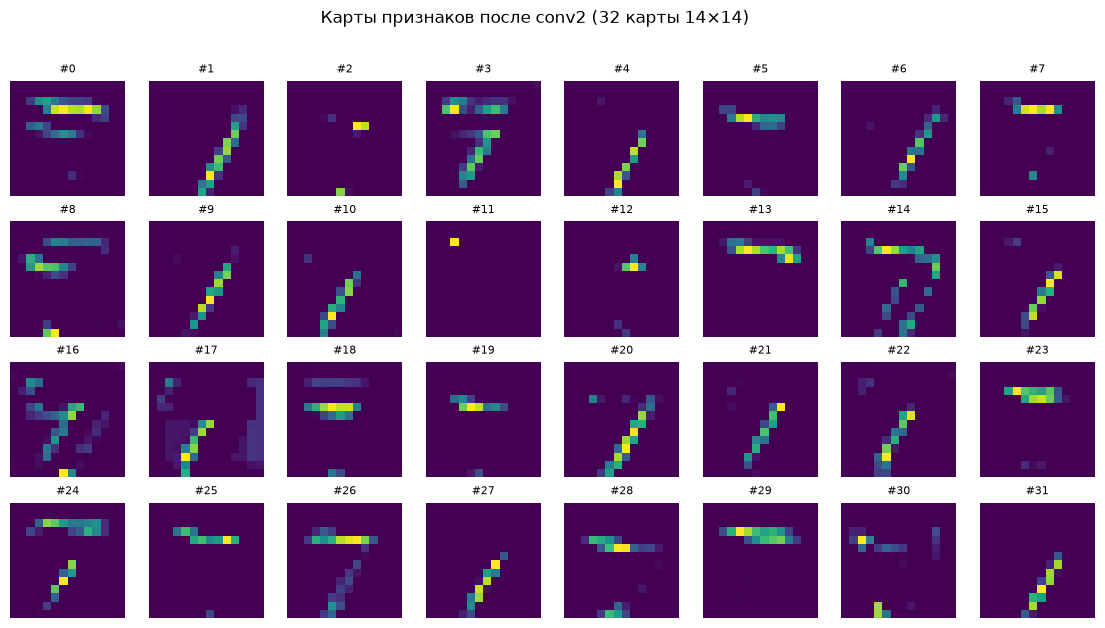

In [41]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

with torch.no_grad():
    preds = torch.cat([cnn(xb).argmax(1) for xb, _ in test_loader])
cm = confusion_matrix(test_set.targets, preds)
ConfusionMatrixDisplay(cm).plot(cmap='Purples', colorbar=False)
plt.title('Матрица ошибок MNIST')
plt.show()
print('Ошибок:', int(cm.sum() - np.trace(cm)), 'из', int(cm.sum()))

w = cnn.conv1.weight.detach()[:, 0]
fig, ax = plt.subplots(2, 8, figsize=(12, 3.2))
for i, a in enumerate(ax.flat):
    a.imshow(w[i], cmap='gray'); a.axis('off'); a.set_title(f'#{i}', fontsize=8)
plt.suptitle('Фильтры первого свёрточного слоя (3×3)')
plt.show()

img, label = test_set[0]
with torch.no_grad():
    maps1 = torch.relu(cnn.conv1(img.unsqueeze(0)))[0]
    maps2 = torch.relu(cnn.conv2(cnn.pool(maps1.unsqueeze(0))))[0]
plt.imshow(img[0], cmap='gray'); plt.title(f'Входное изображение: цифра {label}'); plt.axis('off'); plt.show()

fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for i, a in enumerate(ax.flat):
    a.imshow(maps1[i], cmap='viridis'); a.axis('off'); a.set_title(f'#{i}', fontsize=8)
plt.suptitle('Карты признаков после conv1 (16 карт 28×28)')
plt.show()

fig, ax = plt.subplots(4, 8, figsize=(14, 7))
for i, a in enumerate(ax.flat):
    a.imshow(maps2[i], cmap='viridis'); a.axis('off'); a.set_title(f'#{i}', fontsize=8)
plt.suptitle('Карты признаков после conv2 (32 карты 14×14)')
plt.show()

In [42]:
# Точность и полнота по каждой цифре
from sklearn.metrics import precision_score, recall_score
per_class = pd.DataFrame({'цифра': range(10),
                          'объектов в тесте': np.bincount(test_set.targets.numpy()),
                          'precision': precision_score(test_set.targets, preds, average=None),
                          'recall': recall_score(test_set.targets, preds, average=None)})
per_class.round(4)

,цифра,объектов в тесте,precision,recall
0,0,980,0.9869,0.9980
1,1,1135,0.9956,0.9965
2,2,1032,0.9971,0.9826
3,3,1010,0.9711,0.9980
4,4,982,0.9808,0.9868
5,5,892,0.9898,0.9776
6,6,958,0.9979,0.9718
7,7,1028,0.9807,0.9893
8,8,974,0.9906,0.9784
9,9,1009,0.9735,0.9812


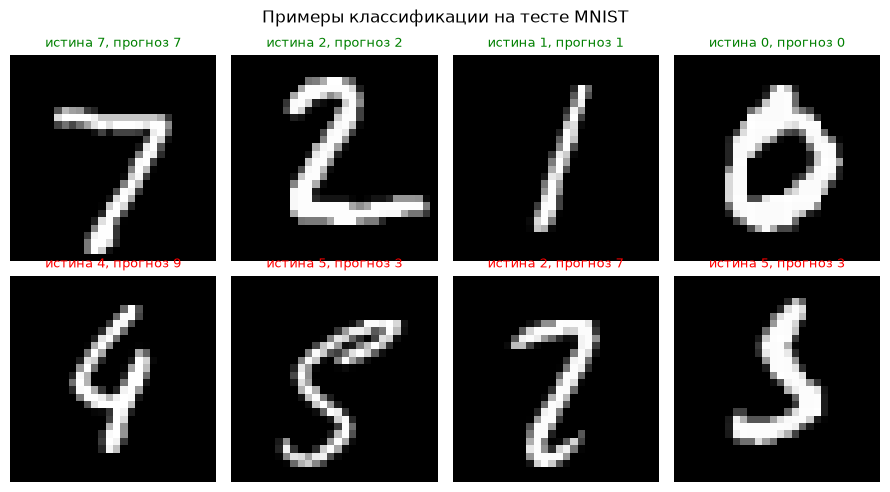

In [43]:
# Примеры верных и ошибочных ответов сети
right = torch.nonzero(preds == test_set.targets).squeeze()
wrong = torch.nonzero(preds != test_set.targets).squeeze()
fig, ax = plt.subplots(2, 4, figsize=(9, 5))
for row, idx_list, color in [(0, right[:4], 'green'), (1, wrong[:4], 'red')]:
    for a, i in zip(ax[row], idx_list):
        img_w, true_w = test_set[i.item()]
        a.imshow(img_w[0], cmap='gray')
        a.set_title(f'истина {true_w}, прогноз {preds[i].item()}', fontsize=9, color=color)
        a.axis('off')
plt.suptitle('Примеры классификации на тесте MNIST')
plt.tight_layout()
plt.show()

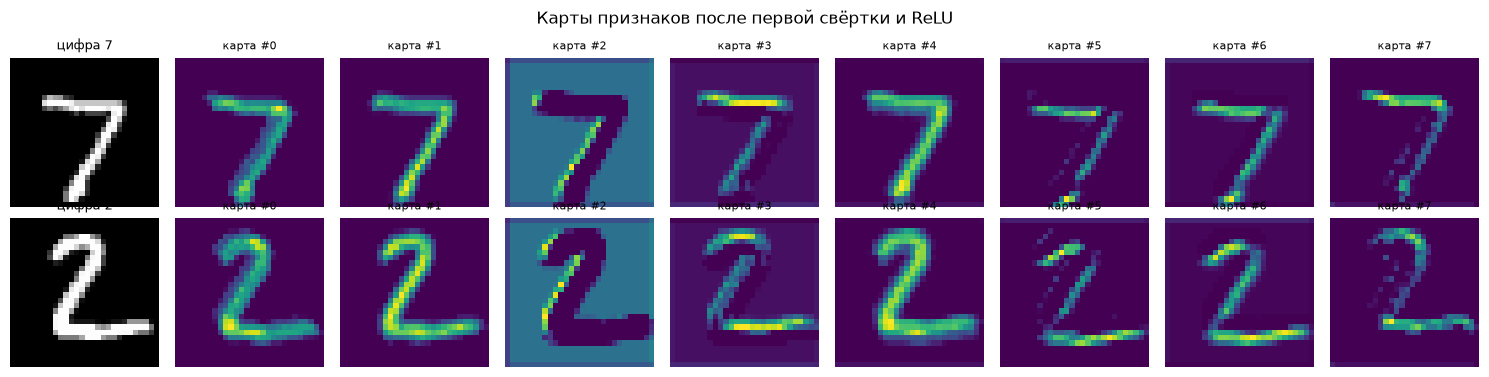

In [44]:
# Карты признаков первого слоя после ReLU для цифр 7 и 2 (первые два изображения тестовой выборки)
fig, ax = plt.subplots(2, 9, figsize=(15, 3.8))
for row, i in enumerate([0, 1]):
    img_d, lab_d = test_set[i]
    with torch.no_grad():
        maps = torch.relu(cnn.conv1(img_d.unsqueeze(0)))[0]
    ax[row, 0].imshow(img_d[0], cmap='gray')
    ax[row, 0].set_title(f'цифра {lab_d}', fontsize=9)
    for j in range(8):
        ax[row, j + 1].imshow(maps[j], cmap='viridis')
        ax[row, j + 1].set_title(f'карта #{j}', fontsize=8)
for a in ax.flat:
    a.axis('off')
plt.suptitle('Карты признаков после первой свёртки и ReLU')
plt.tight_layout()
plt.show()

### Выводы по заданию 3
Построенная сеть - два свёрточных слоя с 16 и 32 фильтрами 3×3, после каждого MaxPool 2×2, и два полносвязных слоя (1568 → 128 → 10). После шести эпох она распознаёт 98.6 % цифр тестовой выборки (137 ошибок из 10 000), лучший результат 98.8 % - на 3-й и 5-й эпохах. После 5-й эпохи потери на тесте начинают расти при убывающих потерях на обучающей выборке, поэтому для этой сети достаточно 3–5 эпох. Ошибки возникают в основном между похожими по начертанию цифрами: 5 и 3, 4 и 9, 6 и 4.

По весам видно, что фильтры первого слоя - это детекторы краёв разной ориентации, а карты признаков показывают, какие части изображения каждый фильтр выделяет: весь штрих, отдельные края или фон. Из этих простых признаков второй слой собирает части цифр, а полносвязные слои по ним определяют класс. Свёрточным слоям для этого нужно всего 4 800 параметров из 206 922, потому что каждый фильтр использует одни и те же веса во всех точках изображения.